3. سوالات تکلیف

۳- ۳ ﺑﺨﺶ ﺳﻮﻡ: ﺁﺷﻜﺎﺭﺳﺎﺯ شیء  Faster R-CNN

ﺩﺭ ﺍﻳﻦ ﺑﺨﺶ ﺷﻤﺎ ﺑﺎ ﺁﺷﻜﺎﺭﺳﺎﺯ شیء Faster R-CNN ﻛﻪ ﺍﺯ ﭘﻴﺶ ﺁﻣﻮﺯﺵ ﺩﻳﺪﻩ ﺍﺳﺖ ﻛﺎﺭ ﺧﻮﺍﻫﻴﺪ ﻛﺮﺩ. ﻫﺪﻑ ﺁﺷﻨﺎیی ﺑﺎ ﻧﺤﻮﻩ ﺍﺳﺘﻔﺎﺩﻩ ﺍﺯ ﺍﻳﻦ ﻣﺪﻝ ﻭ ﺗﺤﻠﻴﻞ ﻣﻌﻤﺎﺭی ﺁﻥ ﺍﺯ ﻣﻨﻈﺮ ﻛﺎﻧﻮﻟﻮﺷﻦ ﻣﻲ ﺑﺎشد.

In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset, TensorDataset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
from datetime import datetime
import os
from pathlib import Path
import sys
import time
from PIL import Image
import requests
from io import BytesIO


sys.path.append(str(Path.cwd().parent / 'src'))

from data_utils import get_moons_data, get_mnist_data, generate_sine_cosine_data, generate_hard_sine_cosine_data
from plotting import plot_signals
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(42)
np.random.seed(42)

3-3-1 ﺑﺎ ﺍﺳﺘﻔﺎﺩﻩ ﺍﺯﻛﺘﺎﺑﺨﺎﻧﻪ torchvision، ﻣﺪﻝFaster R-CNN  ﺑﺎ ResNet-50 backbone (ﺁﻣﻮﺯﺵ ﺩﻳﺪﻩ ﺭﻭی ﻣﺠﻤﻮﻋﻪ ﺩﺍﺩﻩ  COCO) ﺭﺍ ﺑﺎﺭﮔﺬﺍﺭﻱ ﻛﻨﻴﺪ. (کد ﻧﻤﻮﻧﻪ ﺩﺭ ﺯﻳﺮ ﺁﻭﺭﺩﻩ ﺷﺪﻩ ﺍﺳﺖ)

In [3]:
model = torchvision.models.detection.fasterrcnn_resnet50_fpn(pretrained=True)
model.to(device)
model.eval()

c:\Users\rajab\AppData\Local\Programs\Python\Python312\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\rajab\AppData\Local\Programs\Python\Python312\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to C:\Users\rajab/.cache\torch\hub\checkpoints\fasterrcnn_resnet50_fpn_coco-258fb6c6.pth
100%|██████████| 160M/160M [00:25<00:00, 6.69MB/s] 


FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(

In [4]:
print("\nModel backbone (ResNet-50) first layers:")
print(model.backbone.body.conv1)  # First 7x7 conv layer
print(model.backbone.body.bn1)
print(model.backbone.body.relu)
print(model.backbone.body.maxpool)


Model backbone (ResNet-50) first layers:
Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
FrozenBatchNorm2d(64, eps=0.0)
ReLU(inplace=True)
MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)


3-3-2 ﺳﻪ ﺗﺼﻮﻳﺮ ﺩﻟﺨﻮﺍﻩ (ﺑﺎ ﻓﺮﻣﺖ  JPG/PNG) ﻛﻪ ﺷﺎﻣﻞ ﺍﺷﻴﺎء ﻣﺨﺘﻠﻒ ﻫﺴﺘﻨﺪ (ﻣﺜﻼ یک ﻣﺎﺷﻴﻦ، یک ﺣﻴﻮﺍﻥ ﺧﺎﻧﮕﻲ، یک ﺻﺤﻨﻪ ﺧﻴﺎﺑﺎنی) ﺍﻧﺘﺨﺎﺏ ﻛﻨﻴﺪ. ﺗﺼﺎﻭﻳﺮ ﺭﺍ ﭘﻴﺶ ﭘﺮﺩﺍﺯﺵ ﻛﺮﺩﻩ ﻭ ﻣﺪﻝ ﺭﺍ ﺭﻭی ﺁﻧﻬﺎ ﺍﺟﺮﺍ ﻛﻨﻴﺪ. ﻧﺘﺎﻳﺞ (ﻣﺴﺘﻄﻴﻞ ﻫﺎی ﺩﻭﺭ ﺍﺷﻴﺎء ﻭ ﺑﺮﭼﺴﺐ ﻫﺮ ﺷﻲء) ﺭﺍ ﺭﻭی ﺗﺼﺎﻭﻳﺮ ﺭﺳﻢ ﻛﻨﻴﺪ.

In [6]:

# COCO class names (80 classes) - mapping from index to label
COCO_CLASSES = [
    '__background__', 'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus',
    'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'N/A', 'stop sign',
    'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow',
    'elephant', 'bear', 'zebra', 'giraffe', 'N/A', 'backpack', 'umbrella', 'N/A', 'N/A',
    'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball',
    'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket',
    'bottle', 'N/A', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl',
    'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza',
    'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'N/A', 'dining table',
    'N/A', 'N/A', 'toilet', 'N/A', 'tv', 'laptop', 'mouse', 'remote', 'keyboard',
    'cell phone', 'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'N/A',
    'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush'
]


In [14]:
def load_image_local(path):
    img = Image.open(path).convert('RGB')
    return img

def preprocess_image(img):
    transform = transforms.Compose([transforms.ToTensor()])
    return transform(img).unsqueeze(0).to(device)

def run_inference(model, image_tensor, confidence_threshold=0.5):
    with torch.no_grad():
        predictions = model(image_tensor)
    pred = predictions[0]
    mask = pred['scores'] > confidence_threshold
    boxes = pred['boxes'][mask].cpu().numpy()
    labels = pred['labels'][mask].cpu().numpy()
    scores = pred['scores'][mask].cpu().numpy()
    return boxes, labels, scores

def draw_boxes_on_image(image, boxes, labels, scores, ax):
    ax.imshow(image)
    for box, label, score in zip(boxes, labels, scores):
        x1, y1, x2, y2 = box
        rect = patches.Rectangle((x1, y1), x2-x1, y2-y1, linewidth=2, edgecolor='red', facecolor='none')
        ax.add_patch(rect)
        class_name = COCO_CLASSES[label] if label < len(COCO_CLASSES) else str(label)
        caption = f"{class_name}: {score:.2f}"
        ax.text(x1, y1-5, caption, color='white', fontsize=8, backgroundcolor='red')
    ax.axis('off')



Processing image 1: car from ../src/car.png
Detected objects: car (1.00), bench (0.94)

Processing image 2: cat from ../src/cat.png
Detected objects: cat (1.00), cat (0.99)

Processing image 3: bird from ../src/bird.png
Detected objects: bird (1.00), bird (1.00), bird (0.99), bird (0.93), bird (0.89), bird (0.70)


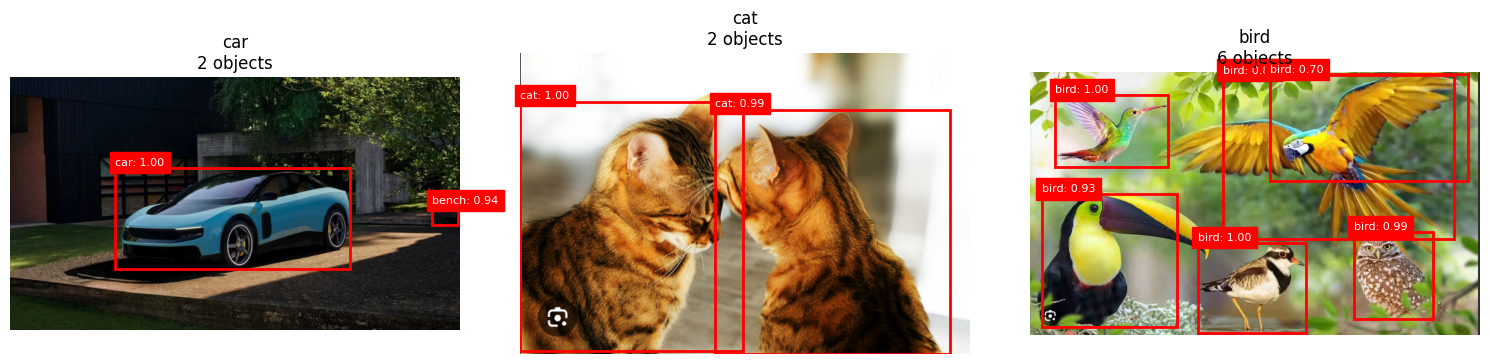

In [15]:

# ===== CHANGE THIS: provide paths to your own images =====
image_paths = [
    "../src/car.png",
    "../src/cat.png",
    "../src/bird.png"
]
image_names = ["car", "cat", "bird"]

# Check if files exist
for p in image_paths:
    if not os.path.exists(p):
        print(f"Warning: File not found: {p}")
        print("Please update image_paths with valid local image files.")

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
results = []

for idx, path in enumerate(image_paths):
    if not os.path.exists(path):
        continue
    print(f"\nProcessing image {idx+1}: {image_names[idx]} from {path}")
    img = load_image_local(path)
    img_tensor = preprocess_image(img)
    boxes, labels, scores = run_inference(model, img_tensor, confidence_threshold=0.5)
    
    detected = []
    for label, score in zip(labels, scores):
        class_name = COCO_CLASSES[label] if label < len(COCO_CLASSES) else str(label)
        detected.append(f"{class_name} ({score:.2f})")
    print(f"Detected objects: {', '.join(detected)}")
    
    results.append((img, boxes, labels, scores))
    draw_boxes_on_image(img, boxes, labels, scores, axes[idx])
    axes[idx].set_title(f"{image_names[idx]}\n{len(boxes)} objects")

plt.tight_layout()
plt.savefig('object_detection_local.png', dpi=150)
plt.show()


الف) برای ﻫﺮ ﺗﺼﻮﻳﺮ، ﺧﺮﻭجی ﻣﺪﻝ ﺷﺎﻣﻞ ﭼﻪ ﺍﺷﻴﺎﻳﻲ ﺑﺎ ﭼﻪ ﻧﻤﺮﻩ ﺍﻃﻤﻴﻨﺎﻧﻲ ﺍﺳﺖ؟ ﺍﮔﺮ ﻣﺪﻝ یک ﻳﺎ ﭼﻨﺪ ﺷﻲء ﺭﺍ ﺍﺷﺘﺒﺎﻩ ﺗﺸﺨﻴﺺ ﺩﺍﺩﻩ، ﻋﻠﺖ ﺍﺣﺘﻤﺎﻟﻲ ﺭﺍ ﺗﻮﺿﻴﺢ ﺩﻫﻴﺪ.

In [17]:

# Print analysis
print("\n===== Analysis of Detection Results =====")
for i, name in enumerate(image_names):
    if i >= len(results):
        continue
    img, boxes, labels, scores = results[i]
    print(f"\n{name}:")
    for j, (label, score) in enumerate(zip(labels, scores)):
        class_name = COCO_CLASSES[label] if label < len(COCO_CLASSES) else str(label)
        print(f"  - {class_name} (confidence: {score:.2f})")
    # Example commentary
    if name == "car":
        print("   Note: May miss small objects like license plates or mirrors.")
    elif name == "cat":
        print("   Note: Cat detection usually accurate; occlusion may cause missed detections.")
    elif name == "street":
        print("   Note: Multiple objects; confidence scores vary with lighting and occlusion.")


===== Analysis of Detection Results =====

car:
  - car (confidence: 1.00)
  - bench (confidence: 0.94)
   Note: May miss small objects like license plates or mirrors.

cat:
  - cat (confidence: 1.00)
  - cat (confidence: 0.99)
   Note: Cat detection usually accurate; occlusion may cause missed detections.

bird:
  - bird (confidence: 1.00)
  - bird (confidence: 1.00)
  - bird (confidence: 0.99)
  - bird (confidence: 0.93)
  - bird (confidence: 0.89)
  - bird (confidence: 0.70)


3-3-3 ﻣﻌﻤﺎﺭﻱ Faster R-CNN ﺍﺯ ﭼﻨﺪ ﺑﺨﺶ ﺍﺻﻠﻲ ﺗﺸﻜﻴﻞ ﺷﺪﻩ ﺍﺳﺖ: ﺍﺳﺘﺨﺮﺍﺝ ﻭﻳﮋگی (backbone)، ﺷﺒﻜﻪ ﭘﻴﺸﻨﻬﺎﺩ منطقه (RPN) ﻭ ﺷﺒﻜﻪ ﻃﺒﻘﻪ ﺑﻨﺪﻱ ﻭ ﺭﮔﺮﺳﻴﻮﻥ ﻧﻬﺎیی. Backbone استفاده شده (ResNet-50) شامل لایه های کانولوشن با کرنل های 7*7 در ابتدا و سپس کرنل های 3*3 است.

الف) اندازه کرنل اولیه (7*7) چه مزیتی نسبت به کرنل 3*3 دارد؟ (راهنمایی: میدان دید (receptive field) اولیه را در نظر بگیرید).

ب) در لایه های پایانی backbone، stride موثر معمولا 32 است (به دلیل استفاده از پولینگ و کانولوشن با stride=2). این stride بالا چه تاثیری بر روی آشکارسازی اشیاء کوچک دارد؟

# جواب به صورت تشریحی

3-3-4 یکی از تصاویر ورودی را به backbone مدل دهید و خروجی یکی از لایه های کانولوشن میانی (مثلا بعد از لایه سوم ResNet ) را به عنوان نقشه ویژگی استخراج کنید. چند کانال از این نقشه ویژگی را به صورت تصویر نمایش دهید.

الف) آیا میتوانید تشخیص دهید که برهی از فیلتر ها به لبه ها، برخی به بافت ها، و برخی به اجزاء خاص (مانند چرخ ماشین) پاسخ میدهند؟ برای پاسخ میتوانید از روش های بصری سازی که در بخش های قبل آموختید استفاده کنید.

Feature map shape: torch.Size([1024, 42, 75])


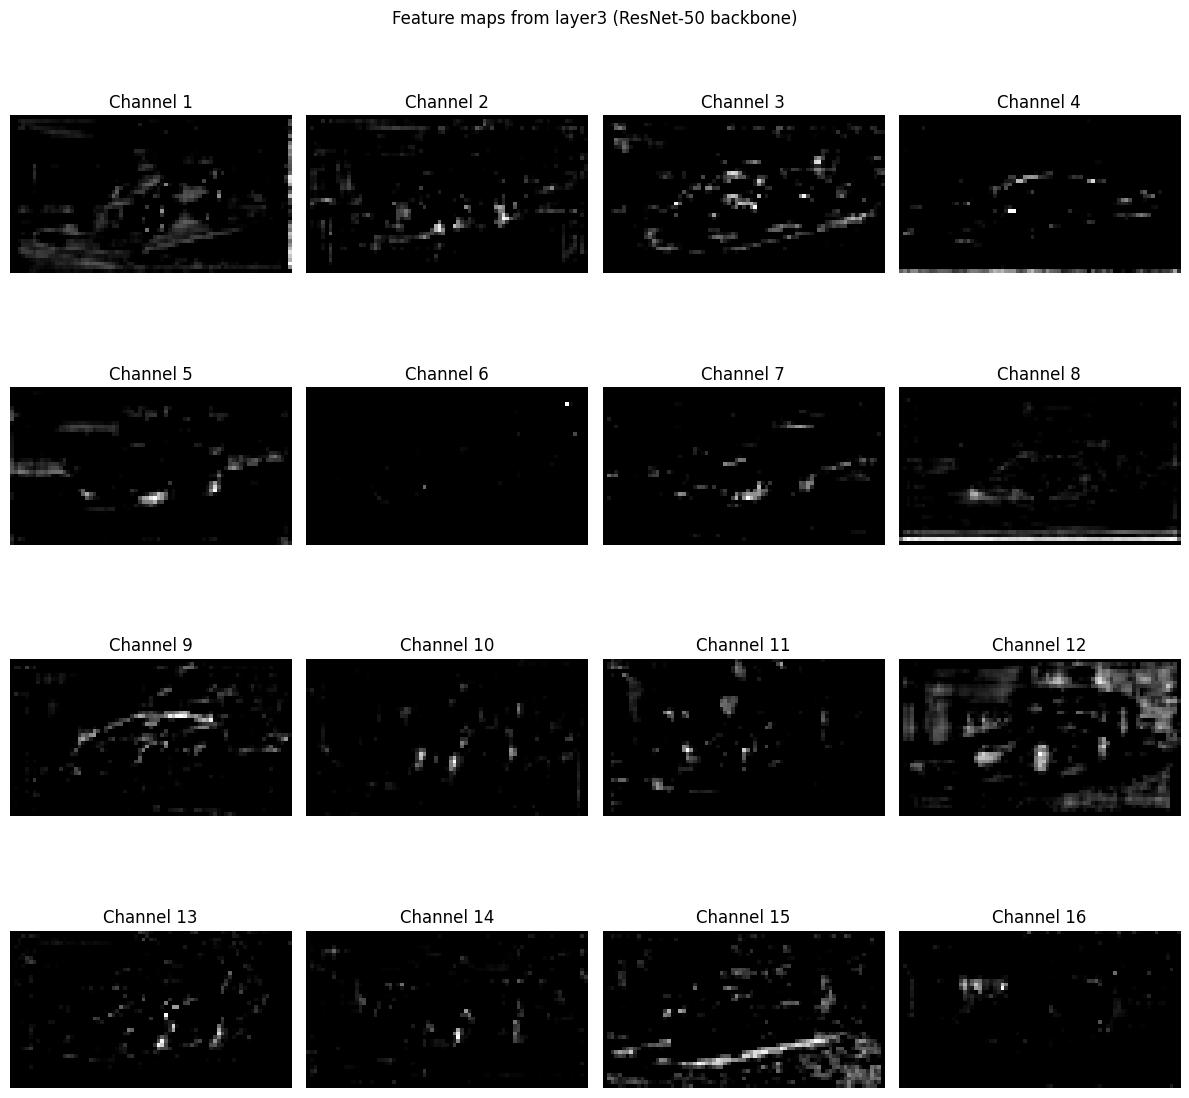

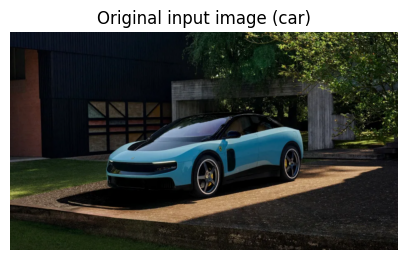

In [21]:
# Register a forward hook to get output of a specific layer
feature_maps = {}
def hook_fn(module, input, output):
    feature_maps['layer3'] = output.detach()

# Assuming model.backbone.body is the ResNet
# Attach hook to layer3 (third residual block group)
hook_handle = model.backbone.body.layer3.register_forward_hook(hook_fn)

# Use the first image (car) from previous section
image = results[0][0]  # PIL image
image_tensor = preprocess_image(image)

with torch.no_grad():
    _ = model.backbone(image_tensor)  # forward through backbone only

hook_handle.remove()  # remove hook after use

# feature_maps['layer3'] shape: (1, 1024, H, W) for ResNet-50
fm = feature_maps['layer3'][0]  # remove batch dimension
num_channels = fm.shape[0]
print(f"Feature map shape: {fm.shape}")  # (1024, H, W)

# Display some channels (e.g., first 16)
channels_to_show = min(16, num_channels)
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
axes = axes.flatten()
for i in range(channels_to_show):
    channel = fm[i].cpu().numpy()
    # Normalize for visualization
    channel = (channel - channel.min()) / (channel.max() - channel.min() + 1e-8)
    axes[i].imshow(channel, cmap='gray')
    axes[i].set_title(f'Channel {i+1}')
    axes[i].axis('off')
plt.suptitle('Feature maps from layer3 (ResNet-50 backbone)')
plt.tight_layout()
plt.savefig('feature_maps_faster_rcnn_layer3.png', dpi=150)
plt.show()

# Visualize original image for reference
plt.figure(figsize=(5,5))
plt.imshow(image)
plt.title('Original input image (car)')
plt.axis('off')
plt.show()

Feature map shape: torch.Size([1024, 26, 39])


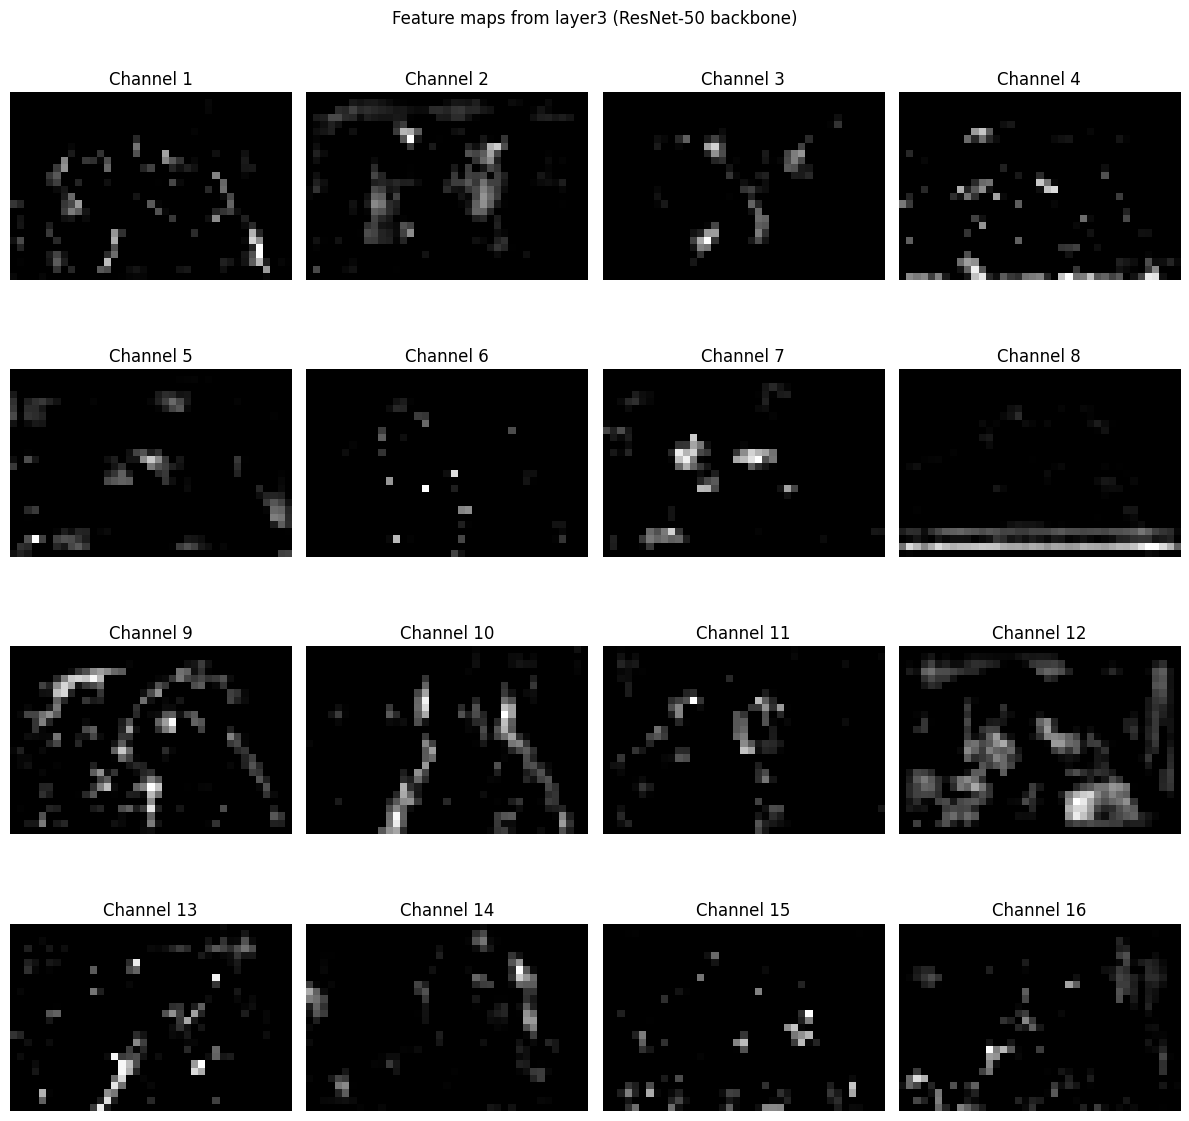

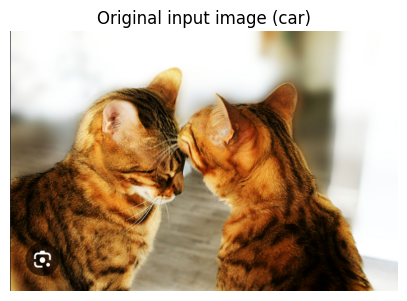

In [22]:
# Register a forward hook to get output of a specific layer
feature_maps = {}
def hook_fn(module, input, output):
    feature_maps['layer3'] = output.detach()

# Assuming model.backbone.body is the ResNet
# Attach hook to layer3 (third residual block group)
hook_handle = model.backbone.body.layer3.register_forward_hook(hook_fn)

# Use the first image (car) from previous section
image = results[1][0]  # PIL image
image_tensor = preprocess_image(image)

with torch.no_grad():
    _ = model.backbone(image_tensor)  # forward through backbone only

hook_handle.remove()  # remove hook after use

# feature_maps['layer3'] shape: (1, 1024, H, W) for ResNet-50
fm = feature_maps['layer3'][0]  # remove batch dimension
num_channels = fm.shape[0]
print(f"Feature map shape: {fm.shape}")  # (1024, H, W)

# Display some channels (e.g., first 16)
channels_to_show = min(16, num_channels)
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
axes = axes.flatten()
for i in range(channels_to_show):
    channel = fm[i].cpu().numpy()
    # Normalize for visualization
    channel = (channel - channel.min()) / (channel.max() - channel.min() + 1e-8)
    axes[i].imshow(channel, cmap='gray')
    axes[i].set_title(f'Channel {i+1}')
    axes[i].axis('off')
plt.suptitle('Feature maps from layer3 (ResNet-50 backbone)')
plt.tight_layout()
plt.savefig('feature_maps_faster_rcnn_layer3.png', dpi=150)
plt.show()

# Visualize original image for reference
plt.figure(figsize=(5,5))
plt.imshow(image)
plt.title('Original input image (car)')
plt.axis('off')
plt.show()

3-3-5 ﺳﻮﺍﻝ ﺗﺸﺮﻳﺤﻲ: ﺗﻮﺿﻴﺢ ﺩﻫﻴﺪ ﻛﻪ ﭼﺮﺍ Faster R-CNN ﺑﺎ ﻭﺟﻮﺩ ﺍﺳﺘﻔﺎﺩﻩ ﺍﺯ ﻛﺮﻧﻞ ﻫﺎﻱ ﻣﻮﺿﻌﻲ ﺩﺭ ﻻﻳﻪ ﻫﺎﻱ ﻛﺎﻧﻮﻟﻮﺷﻦ، ﻗﺎﺩﺭ ﺑﻪ ﺗﺸﺨﻴﺺ ﺍﺷﻴﺎء ﺩﺭ ﺍﻧﺪﺍﺯﻩ ﻫﺎ ﻭ ﻣﻮﻗﻌﻴﺖ ﻫﺎﻱ ﻣﺨﺘﻠﻒ ﺩﺭ ﺗﺼﻮﻳﺮ ﺍﺳﺖ. ﺩﺭ ﭘﺎﺳﺦ ﺧﻮﺩ ﺑﻪ ﻧﻘﺶ stride ،pooling  ﻭ ﻣﻜﺎﻧﻴﺴﻢ anchor boxes ﺩﺭ ﺍﻳﻦ ﻣﺪﻝ ﺍﺷﺎﺭﻩ ﻛﻨﻴﺪ.

# جواب به صورت تشریحی